# Lab 1-07：換供應商——一個客戶端連 Ollama、OpenRouter、DeepSeek，再看 Anthropic 哪裡不一樣

**目標**：用同一段程式碼、只換 `base_url` 和金鑰，就能連到不同的模型供應商；再把格式不一樣的 Anthropic 請求攤開來比。

**你會學到**
- 「OpenAI 相容」是什麼意思，為什麼大家都支援它
- Ollama 自己的原生 API 能多告訴你什麼（模型層數、量化、每秒幾個 token）
- OpenRouter：一把金鑰連幾百個模型
- Anthropic Messages API 的三個格式差異：system 放外面、content 是區塊陣列、`max_tokens` 必填

**前置**：Ollama 有在跑（Lab 1-04）。雲端都是選填，在 `.env` 填了才會實際呼叫，沒填就印出請求長相並略過：
`OPENAI_API_KEY`、`OPENROUTER_API_KEY`、`DEEPSEEK_API_KEY`、`ANTHROPIC_API_KEY`。

**對應投影片**：「開放權重與商業 API」「依顯存選本地模型」「選型：商業 API 模型」「選型：開放權重模型」

```
OpenAI 相容客戶端（只換 base_url、金鑰、模型名稱）
   ├──► Ollama       http://localhost:11434/v1
   ├──► OpenRouter   https://openrouter.ai/api/v1
   ├──► DeepSeek     https://api.deepseek.com/v1
   └──► OpenAI       https://api.openai.com/v1

OpenAI 格式的 messages
   └──► to_anthropic()：system 拿到外面、content 變區塊、補上 max_tokens
          └──► Anthropic  https://api.anthropic.com/v1/messages
```

*圖：大部分供應商說同一種「方言」，換網址就能連；Anthropic 說另一種，要先轉一次格式。*

## Step 1：把供應商寫成一張表

每家供應商只差三件事：網址、金鑰、模型名稱。金鑰一律從環境變數讀，表裡只記「變數叫什麼」。

In [1]:
import json
import os
import time

import requests
from dotenv import load_dotenv

load_dotenv()

OLLAMA_V1 = os.getenv("LOCAL_BASE_URL", "http://localhost:11434/v1")
OLLAMA = OLLAMA_V1.removesuffix("/v1")  # 原生 API 在 /api/...
LOCAL_MODEL = os.getenv("LOCAL_MODEL", "qwen2.5:3b")

PROVIDERS = {
    "Ollama": {"base_url": OLLAMA_V1, "key_env": None, "model": LOCAL_MODEL},
    "OpenAI": {"base_url": "https://api.openai.com/v1", "key_env": "OPENAI_API_KEY", "model": "gpt-4o-mini"},
    "OpenRouter": {"base_url": "https://openrouter.ai/api/v1", "key_env": "OPENROUTER_API_KEY", "model": None},  # Step 5 再挑
    "DeepSeek": {"base_url": "https://api.deepseek.com/v1", "key_env": "DEEPSEEK_API_KEY", "model": "deepseek-chat"},
}


def api_key(name: str) -> str | None:
    env = PROVIDERS[name]["key_env"]
    return "ollama" if env is None else os.getenv(env)  # Ollama 不檢查金鑰，但 SDK 要求非空字串


for name, p in PROVIDERS.items():
    print(f"{name:<11} {p['base_url']:<30} 金鑰：{'有' if api_key(name) else '沒有，會略過'}")

Ollama      http://localhost:11434/v1      金鑰：有
OpenAI      https://api.openai.com/v1      金鑰：有
OpenRouter  https://openrouter.ai/api/v1   金鑰：沒有，會略過
DeepSeek    https://api.deepseek.com/v1    金鑰：沒有，會略過


## Step 2：Ollama 原生 API——本機有哪些模型

除了 `/v1/...` 這組 OpenAI 相容端點，Ollama 還有自己的 `/api/...`。`/api/tags` 列出本機模型，資訊比 `/v1/models` 多：
參數量、量化等級、檔案大小、能做什麼（對話、工具呼叫、embedding）。

In [2]:
tags = requests.get(f"{OLLAMA}/api/tags", timeout=10).json()["models"]
print(f"{'模型':<16}{'參數量':>8}{'量化':>9}{'檔案':>9}  能力")
for m in tags:
    d = m["details"]
    print(f"{m['name']:<16}{d['parameter_size']:>8}{d['quantization_level']:>9}{m['size'] / 1e9:>7.1f}GB  {m.get('capabilities', [])}")

模型                   參數量       量化       檔案  能力
bge-m3:latest    566.70M      F16    1.2GB  ['embedding']
qwen2.5:3b          3.1B   Q4_K_M    1.9GB  ['completion', 'tools']


`Q4_K_M` 的意思是權重壓成約 4 bit。3B 參數若用 fp16 要 6GB 以上，壓完不到 2GB，這是本機跑得動的關鍵。

## Step 3：`/api/show`——打開模型看規格

這裡的數字，就是 Lab 1-02、1-03 講過的那些東西：幾層、向量多寬、幾個 attention 頭、context 多長。

In [3]:
show = requests.post(f"{OLLAMA}/api/show", json={"model": LOCAL_MODEL}, timeout=30).json()
info = show["model_info"]
arch = info["general.architecture"]

spec = {
    "參數量": f"{info['general.parameter_count'] / 1e9:.2f}B",
    "Transformer 層數": info[f"{arch}.block_count"],
    "向量維度（embedding）": info[f"{arch}.embedding_length"],
    "attention 頭數（Q）": info[f"{arch}.attention.head_count"],
    "attention 頭數（K、V）": info[f"{arch}.attention.head_count_kv"],
    "context 上限": info[f"{arch}.context_length"],
    "能力": show.get("capabilities"),
}
for k, v in spec.items():
    print(f"{k:<20} {v}")

參數量                  3.09B
Transformer 層數       36
向量維度（embedding）      2048
attention 頭數（Q）      16
attention 頭數（K、V）    2
context 上限           32768
能力                   ['completion', 'tools']


Q 有 16 個頭、K 和 V 只有 2 個：這叫 GQA，多個 Q 頭共用一組 K、V，生成時要存的 KV cache 少了 8 倍。

`template` 是對話模板：`messages` 陣列送進來之後，Ollama 用它把 system、user、assistant 拼成模型真正看到的一長串文字。

In [4]:
# 模板很長（還包含工具呼叫的格式），只挑出跟角色有關的那幾行
for line in show["template"].splitlines():
    if "im_start" in line:
        print(line.strip())

{{- if or .System .Tools }}<|im_start|>system
{{- if eq .Role "user" }}<|im_start|>user
{{ else if eq .Role "assistant" }}<|im_start|>assistant
{{- else if eq .Role "tool" }}<|im_start|>user
{{- if and (ne .Role "assistant") $last }}<|im_start|>assistant
{{- if .System }}<|im_start|>system
{{ end }}{{ if .Prompt }}<|im_start|>user
{{ end }}<|im_start|>assistant


看到 `<|im_start|>system`、`<|im_start|>user` 了嗎？「角色」在模型眼裡只是幾個特殊 token。
這也說明為什麼換模型時，請求格式可以不變：模板由伺服器負責套。

## Step 4：同一題，問 OpenAI 相容端點和 Ollama 原生端點

兩邊的請求和回應長得不一樣，但背後是同一個模型。注意幾個名稱差異：

| | OpenAI 相容 `/v1/chat/completions` | Ollama 原生 `/api/chat` |
|---|---|---|
| 抽樣參數 | 放最外層：`temperature`、`max_tokens` | 放 `options` 裡：`temperature`、`num_predict` |
| 串流 | 預設關 | **預設開**，要關得寫 `"stream": false` |
| 回答 | `choices[0].message.content` | `message.content` |
| 用量 | `usage.prompt_tokens`、`completion_tokens` | `prompt_eval_count`、`eval_count`，還有各段耗時（奈秒） |

In [5]:
question = [
    {"role": "system", "content": "你是海賊王百科，回答一句話。"},
    {"role": "user", "content": "草帽海賊團的船叫什麼名字？"},
]

compat = requests.post(f"{OLLAMA_V1}/chat/completions", timeout=120, json={
    "model": LOCAL_MODEL, "messages": question, "temperature": 0, "max_tokens": 60,
}).json()
native = requests.post(f"{OLLAMA}/api/chat", timeout=120, json={
    "model": LOCAL_MODEL, "messages": question, "stream": False,
    "options": {"temperature": 0, "num_predict": 60},
}).json()

print("--- OpenAI 相容端點的回應")
print(json.dumps(compat, ensure_ascii=False, indent=2))
print("--- Ollama 原生端點的回應")
print(json.dumps(native, ensure_ascii=False, indent=2))

--- OpenAI 相容端點的回應
{
  "id": "chatcmpl-511",
  "object": "chat.completion",
  "created": 1795015744,
  "model": "qwen2.5:3b",
  "system_fingerprint": "fp_ollama",
  "choices": [
    {
      "index": 0,
      "message": {
        "role": "assistant",
        "content": "草帽海賊團的船叫作「飞龙号」。"
      },
      "finish_reason": "stop"
    }
  ],
  "usage": {
    "prompt_tokens": 36,
    "prompt_tokens_details": {
      "cached_tokens": 35
    },
    "completion_tokens": 17,
    "total_tokens": 53
  }
}
--- Ollama 原生端點的回應
{
  "model": "qwen2.5:3b",
  "created_at": "2026-11-18T15:29:10.249993373Z",
  "message": {
    "role": "assistant",
    "content": "草帽海賊團的船叫作「飞龙号」。"
  },
  "done": true,
  "done_reason": "stop",
  "total_duration": 5958351393,
  "load_duration": 780871,
  "prompt_eval_count": 36,
  "prompt_eval_cached_count": 35,
  "prompt_eval_duration": 21454000,
  "eval_count": 17,
  "eval_duration": 321095000
}


原生回應多了一串計時欄位，單位是奈秒。拿來算「每秒生成幾個 token」：

In [6]:
ns = 1e9
print(f"總耗時：{native['total_duration'] / ns:.2f} 秒")
print(f"載入模型：{native['load_duration'] / ns:.2f} 秒（模型已在顯存裡就接近 0）")
print(f"讀 prompt：{native['prompt_eval_count']} token，{native['prompt_eval_duration'] / ns:.2f} 秒")
print(f"生成：{native['eval_count']} token，{native['eval_duration'] / ns:.2f} 秒"
      f" → {native['eval_count'] / (native['eval_duration'] / ns):.1f} token/秒")

總耗時：5.96 秒
載入模型：0.00 秒（模型已在顯存裡就接近 0）
讀 prompt：36 token，0.02 秒
生成：17 token，0.32 秒 → 52.9 token/秒


讀 prompt 是一次平行算完（很快）；生成是一個一個 token 吐（Lab 1-02 的迴圈），比讀 prompt 慢得多。
如果「總耗時」遠大於「載入＋讀 prompt＋生成」，多出來的時間是在排隊：同一台 Ollama 有別人在用（上課時全班共用一台就會這樣）。

另外，答案本身是錯的：草帽海賊團的船是千陽號（早期是黃金梅利號），還夾了簡體字。3B 小模型的常態，模組 3 的 RAG 會處理。

## Step 5：OpenRouter——一把金鑰，幾百個模型

OpenRouter 是一個轉接站：你只跟它拿一把金鑰，它幫你轉送到各家模型。模型名稱寫成 `廠商/模型`。
它的模型清單是公開的，不用金鑰就能查，連價格都列出來（單位：美元／每個 token）。

In [7]:
try:
    catalog = requests.get("https://openrouter.ai/api/v1/models", timeout=15).json()["data"]
    print(f"OpenRouter 目前有 {len(catalog)} 個模型")
    qwen = sorted(
        (m for m in catalog if m["id"].startswith("qwen/") and ":" not in m["id"] and float(m["pricing"]["prompt"]) > 0),
        key=lambda m: float(m["pricing"]["prompt"]),
    )
    for m in qwen[:5]:
        print(f"  {m['id']:<35} 輸入 ${float(m['pricing']['prompt']) * 1e6:.2f}／百萬 token，context {m['context_length']:,}")
    PROVIDERS["OpenRouter"]["model"] = qwen[0]["id"]  # 挑最便宜的 Qwen
except (requests.RequestException, KeyError, IndexError) as exc:
    print("查不到 OpenRouter 模型清單：", exc)
    PROVIDERS["OpenRouter"]["model"] = "qwen/qwen-2.5-7b-instruct"
print("等一下 OpenRouter 用：", PROVIDERS["OpenRouter"]["model"])

OpenRouter 目前有 478 個模型
  qwen/qwen3.7-flash                  輸入 $0.03／百萬 token，context 1,000,000
  qwen/qwen3.8-27b                    輸入 $0.06／百萬 token，context 1,024,000
  qwen/qwen3.5-flash-02-23            輸入 $0.07／百萬 token，context 1,000,000
  qwen/qwen3-32b                      輸入 $0.08／百萬 token，context 131,072
  qwen/qwen3.6-35b-a3b                輸入 $0.10／百萬 token，context 262,144
等一下 OpenRouter 用： qwen/qwen3.7-flash


## Step 6：同一個客戶端，換 base_url 就能連

下面的 `ask` 對每家供應商都一樣，只有 `base_url`、金鑰、模型名稱不同。沒有金鑰的就略過，有的就量三次延遲。

In [8]:
from openai import OpenAI, OpenAIError


def ask(name: str, messages: list[dict]) -> tuple[str, float]:
    p = PROVIDERS[name]
    client = OpenAI(base_url=p["base_url"], api_key=api_key(name), timeout=60, max_retries=0)
    t = time.perf_counter()
    r = client.chat.completions.create(model=p["model"], messages=messages, max_tokens=60, temperature=0)
    return r.choices[0].message.content.strip(), time.perf_counter() - t


latency: dict[str, list[float]] = {}
for name in PROVIDERS:
    if not api_key(name):
        print(f"[{name}] 沒有 {PROVIDERS[name]['key_env']}，略過")
        continue
    try:
        runs = [ask(name, question) for _ in range(3)]
    except OpenAIError as exc:
        print(f"[{name}] 失敗：{type(exc).__name__}: {exc}")
        continue
    latency[f"{name}\n{PROVIDERS[name]['model']}"] = [sec for _, sec in runs]
    print(f"[{name}] {runs[0][0]}  （{', '.join(f'{s:.2f}' for _, s in runs)} 秒）")

[Ollama] 草帽海賊團的船叫作「飞龙号」。  （3.53, 3.47, 4.08 秒）
[OpenAI] 草帽海賊團的船叫「千陽號」。  （2.04, 1.14, 0.89 秒）
[OpenRouter] 沒有 OPENROUTER_API_KEY，略過
[DeepSeek] 沒有 DEEPSEEK_API_KEY，略過


「相容」不等於「完全一樣」，常見的小差異：
- OpenAI 的推理模型（例如 `gpt-5` 系列）不收 `max_tokens`，要改用 `max_completion_tokens`，也不一定收 `temperature`。
- OpenRouter 建議加 `HTTP-Referer`、`X-Title` 標頭標明你的應用（選填），用 `extra_headers={...}` 傳。
- 各家的錯誤訊息、速率限制、`usage` 裡多出來的欄位都不同。

所以實務上會像 Lab 1-05 那樣包一層自己的 `chat()`，差異只在那一層處理。

再把 Ollama 原生端點也量三次，等一下一起畫。

In [9]:
native_secs = []
for _ in range(3):
    t = time.perf_counter()
    requests.post(f"{OLLAMA}/api/chat", timeout=120, json={
        "model": LOCAL_MODEL, "messages": question, "stream": False,
        "options": {"temperature": 0, "num_predict": 60},
    }).raise_for_status()
    native_secs.append(time.perf_counter() - t)
latency[f"Ollama 原生\n{LOCAL_MODEL}"] = native_secs
print([f"{s:.2f}" for s in native_secs])

['2.40', '2.65', '2.81']


## Step 7：Anthropic Messages API 長得不一樣

Anthropic（Claude）用自己的格式。同一段對話轉過去，有三個地方要改：

1. **system 放外面**：不是 `messages` 裡的一個角色，而是最外層的 `system` 欄位。
2. **content 是區塊陣列**：每塊有 `type`（`text`、`image`…），回應也是區塊陣列。
3. **`max_tokens` 必填**：OpenAI 格式可以省略，Anthropic 不給就報錯。

另外金鑰放在 `x-api-key` 標頭，還要帶 `anthropic-version`。先手寫一個轉換函式：

In [10]:
ANTHROPIC_MODEL = "claude-opus-5-5"


def to_anthropic(messages: list[dict], model: str, max_tokens: int = 1024) -> dict:
    system = "\n".join(m["content"] for m in messages if m["role"] == "system")
    body = {
        "model": model,
        "max_tokens": max_tokens,
        "messages": [
            {"role": m["role"], "content": [{"type": "text", "text": m["content"]}]}
            for m in messages if m["role"] != "system"
        ],
    }
    if system:
        body["system"] = system
    return body


openai_req = requests.Request(
    "POST", "https://api.openai.com/v1/chat/completions",
    headers={"Authorization": "Bearer <OPENAI_API_KEY>"},
    json={"model": "gpt-4o-mini", "messages": question},
).prepare()
anthropic_req = requests.Request(
    "POST", "https://api.anthropic.com/v1/messages",
    headers={"x-api-key": "<ANTHROPIC_API_KEY>", "anthropic-version": "2023-06-01"},
    json=to_anthropic(question, ANTHROPIC_MODEL),
).prepare()

for title, req in [("OpenAI 格式", openai_req), ("Anthropic 格式", anthropic_req)]:
    print(f"===== {title}：{req.method} {req.url}")
    for h in ["Authorization", "x-api-key", "anthropic-version"]:
        if h in req.headers:
            print(f"{h}: {req.headers[h]}")
    print(json.dumps(json.loads(req.body), ensure_ascii=False, indent=2))

===== OpenAI 格式：POST https://api.openai.com/v1/chat/completions
Authorization: Bearer <OPENAI_API_KEY>
{
  "model": "gpt-4o-mini",
  "messages": [
    {
      "role": "system",
      "content": "你是海賊王百科，回答一句話。"
    },
    {
      "role": "user",
      "content": "草帽海賊團的船叫什麼名字？"
    }
  ]
}
===== Anthropic 格式：POST https://api.anthropic.com/v1/messages
x-api-key: <ANTHROPIC_API_KEY>
anthropic-version: 2023-06-01
{
  "model": "claude-opus-5-5",
  "max_tokens": 1024,
  "messages": [
    {
      "role": "user",
      "content": [
        {
          "type": "text",
          "text": "草帽海賊團的船叫什麼名字？"
        }
      ]
    }
  ],
  "system": "你是海賊王百科，回答一句話。"
}


圖片也一樣要轉。Lab 1-06 的 OpenAI 寫法是 `image_url` 加 data URL；Anthropic 把 base64 和格式分開放：

```python
# OpenAI
{"type": "image_url", "image_url": {"url": "data:image/png;base64,iVBOR..."}}
# Anthropic
{"type": "image", "source": {"type": "base64", "media_type": "image/png", "data": "iVBOR..."}}
```

有 `ANTHROPIC_API_KEY` 就實際送出。回應的 `content` 也是區塊陣列，可能不只一塊（例如模型的思考區塊），
所以要挑出 `type == "text"` 的那幾塊，不能直接拿第一塊。

In [11]:
if os.getenv("ANTHROPIC_API_KEY"):
    t = time.perf_counter()
    r = requests.post(
        "https://api.anthropic.com/v1/messages", timeout=120,
        headers={"x-api-key": os.environ["ANTHROPIC_API_KEY"], "anthropic-version": "2023-06-01"},
        json=to_anthropic(question, ANTHROPIC_MODEL),
    )
    r.raise_for_status()
    data = r.json()
    latency[f"Anthropic\n{ANTHROPIC_MODEL}"] = [time.perf_counter() - t]
    print("區塊種類：", [b["type"] for b in data["content"]])
    print("回答：", "".join(b["text"] for b in data["content"] if b["type"] == "text"))
    print("結束原因：", data["stop_reason"], "用量：", data["usage"])
else:
    print("沒有 ANTHROPIC_API_KEY，略過實際呼叫。回應的骨架是：")
    print('{"content": [{"type": "text", "text": "..."}], "stop_reason": "end_turn", '
          '"usage": {"input_tokens": ..., "output_tokens": ...}}')

沒有 ANTHROPIC_API_KEY，略過實際呼叫。回應的骨架是：
{"content": [{"type": "text", "text": "..."}], "stop_reason": "end_turn", "usage": {"input_tokens": ..., "output_tokens": ...}}


平常寫程式會用官方 SDK（`pip install anthropic`），它幫你處理標頭和重試，但請求的形狀就是上面這樣。

## Step 8：一張圖看完差異

左邊是格式對照，右邊是這次實際量到的延遲（沒有金鑰的供應商不會出現在右邊）。

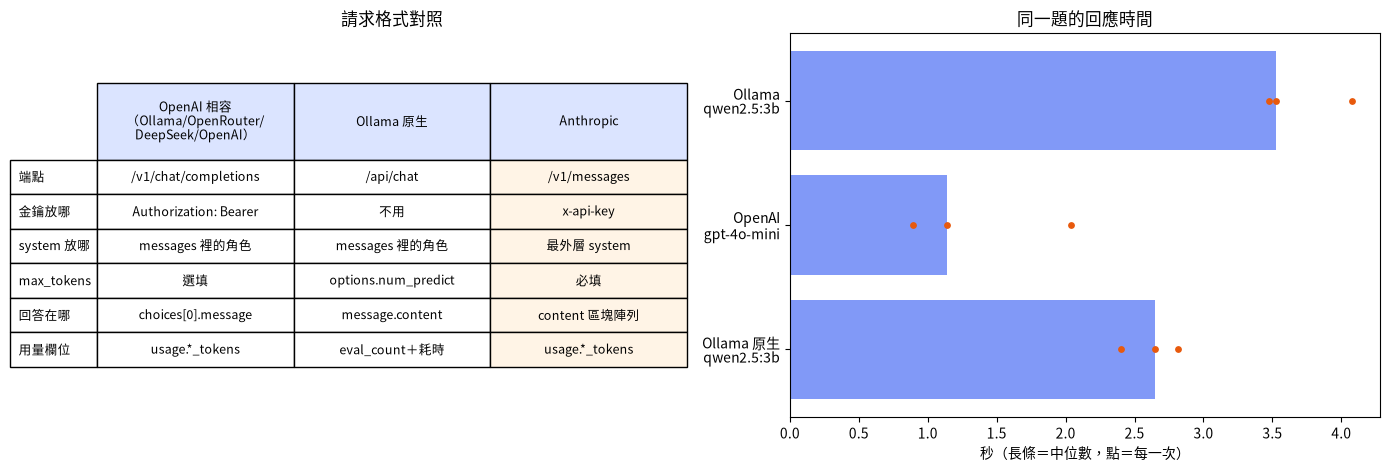

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from course_utils.viz import setup_cjk

setup_cjk()

rows = ["端點", "金鑰放哪", "system 放哪", "max_tokens", "回答在哪", "用量欄位"]
cols = ["OpenAI 相容\n（Ollama/OpenRouter/\nDeepSeek/OpenAI）", "Ollama 原生", "Anthropic"]
cells = [
    ["/v1/chat/completions", "/api/chat", "/v1/messages"],
    ["Authorization: Bearer", "不用", "x-api-key"],
    ["messages 裡的角色", "messages 裡的角色", "最外層 system"],
    ["選填", "options.num_predict", "必填"],
    ["choices[0].message", "message.content", "content 區塊陣列"],
    ["usage.*_tokens", "eval_count＋耗時", "usage.*_tokens"],
]

fig = plt.figure(figsize=(14, 4.8))
ax_t = fig.add_subplot(1, 2, 1)
ax_t.axis("off")
tbl = ax_t.table(cellText=cells, rowLabels=rows, colLabels=cols, loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 2.0)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_height(0.2)
        cell.set_facecolor("#dbe4ff")
    if c == 2 and r > 0:
        cell.set_facecolor("#fff4e6")  # Anthropic 欄標色：跟別人不一樣
ax_t.set_title("請求格式對照")

ax_l = fig.add_subplot(1, 2, 2)
names = list(latency)
med = [np.median(latency[n]) for n in names]
ax_l.barh(names, med, color="#4c6ef5", alpha=0.7)
for i, n in enumerate(names):
    ax_l.scatter(latency[n], [i] * len(latency[n]), color="#e8590c", zorder=3, s=15)
ax_l.invert_yaxis()
ax_l.set_xlabel("秒（長條＝中位數，點＝每一次）")
ax_l.set_title("同一題的回應時間")
plt.tight_layout()
plt.show()

延遲不能只看這一次：本機模型受顯卡和同時有多少人在用影響，雲端受網路和尖峰時段影響。
這張圖要說的是「量得到」——選供應商時把延遲、價格、資料能不能出門一起放上桌比。

## 試試看

1. 申請一把 OpenRouter 金鑰放進 `.env`，在 Step 5 改挑另一個廠商的模型（例如 `meta-llama/` 開頭），重跑 Step 6。
2. 在 Step 4 把原生端點的 `"stream": false` 拿掉，看回應變成什麼樣子；再對照 Lab 1-04 的串流寫法。
3. 寫一個反方向的函式 `from_anthropic(body)`，把 Anthropic 格式轉回 OpenAI 的 `messages`，用 Step 7 的請求驗證轉回來跟 `question` 一樣。

## 小結

- OpenAI 相容格式是業界通用語：Ollama、OpenRouter、DeepSeek 都只要換 `base_url`、金鑰、模型名稱。
- Ollama 原生 API 看得到模型規格、對話模板和每秒 token 數；Anthropic 格式要轉換：system 放外面、content 是區塊、`max_tokens` 必填。
- 差異收在一層自己的客戶端裡處理。模組 1 到這裡結束；模組 2 開始教怎麼把 prompt 寫好、讓輸出變成程式能用的格式。